/content/lib/luccasbi.py:12: SyntaxWarning: invalid escape sequence '\d'
  1. Delta: $\delta[n]$
/content/lib/luccasbi.py:70: SyntaxWarning: invalid escape sequence '\s'
  """## Sinal oscilatório, ou periódico - $A \sin(\omega n + \phi)$
/content/lib/luccasbi.py:134: SyntaxWarning: invalid escape sequence '\m'
  ### Aleatório Gaussiano - $\mathcal{X} \sim \mathcal{N}(\mu, \sigma)$
/content/lib/luccasbi.py:172: SyntaxWarning: invalid escape sequence '\m'
  """### Aleatório uniforme - $\mathcal{X} \sim \mathcal{U} \{a, b\}$


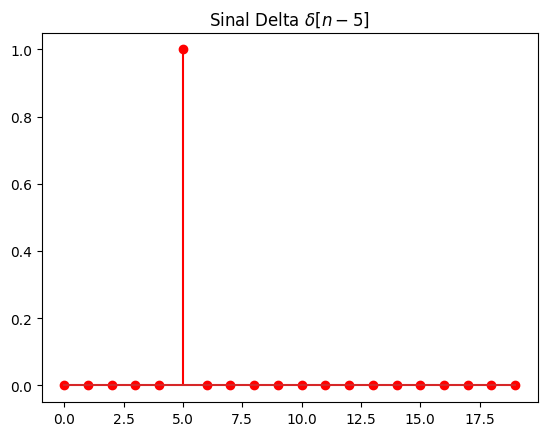

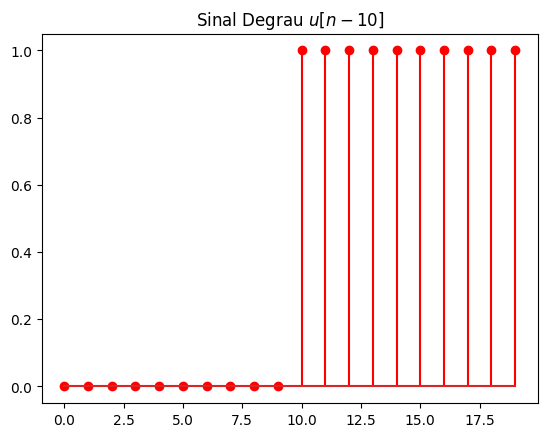

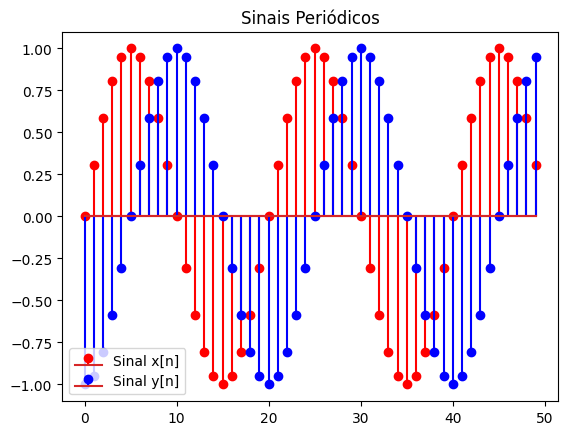

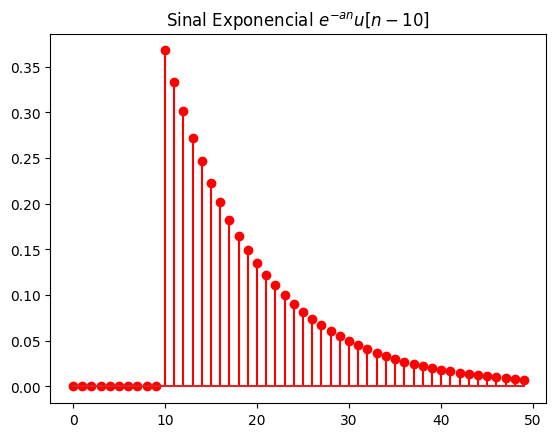

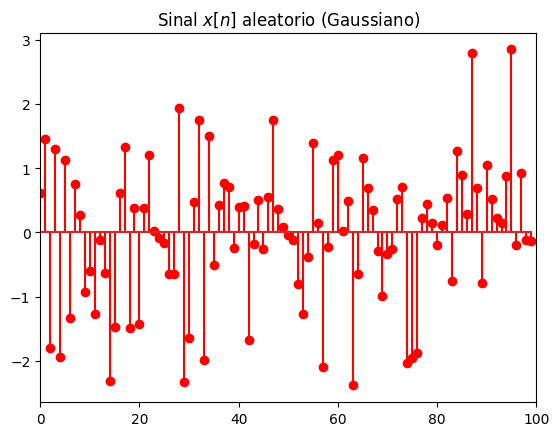

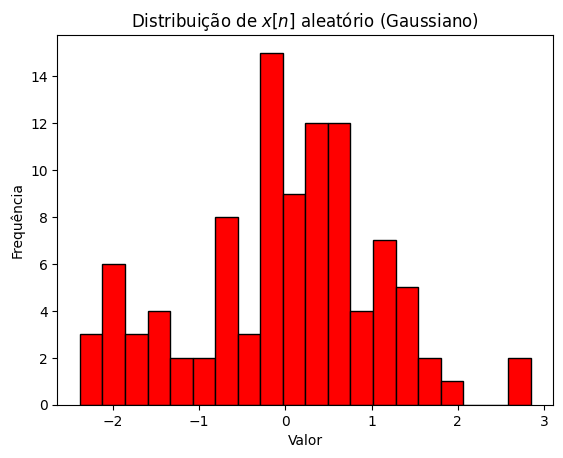

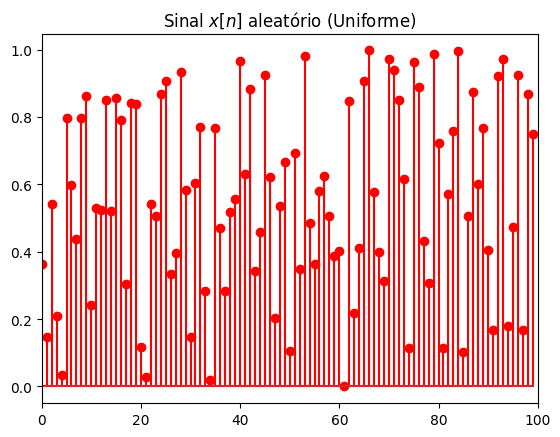

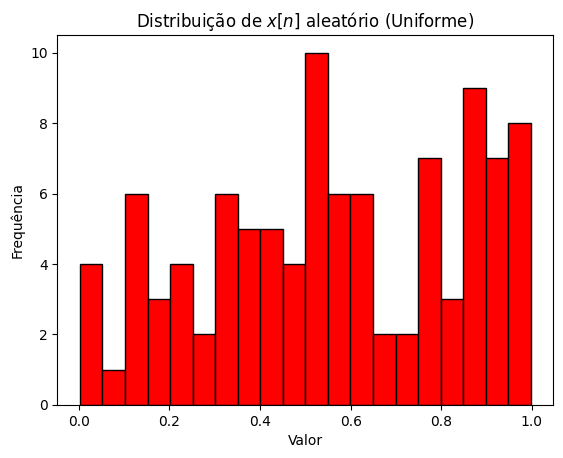

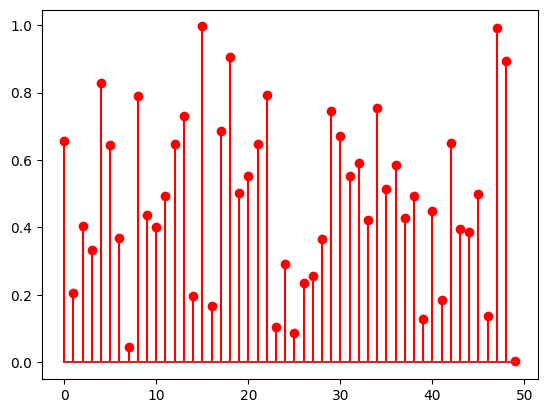

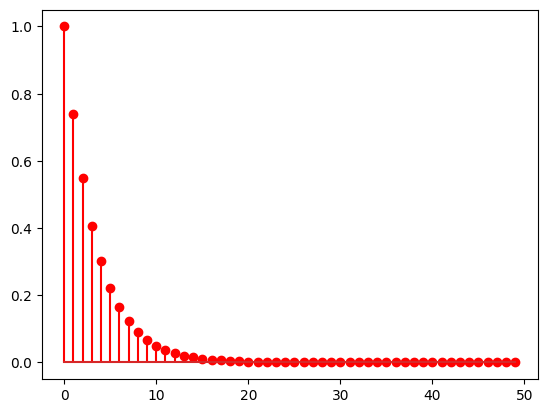

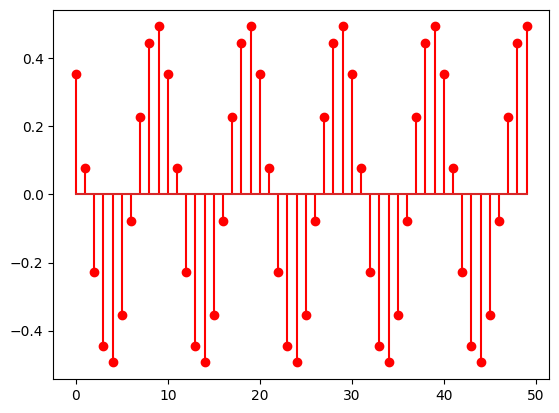

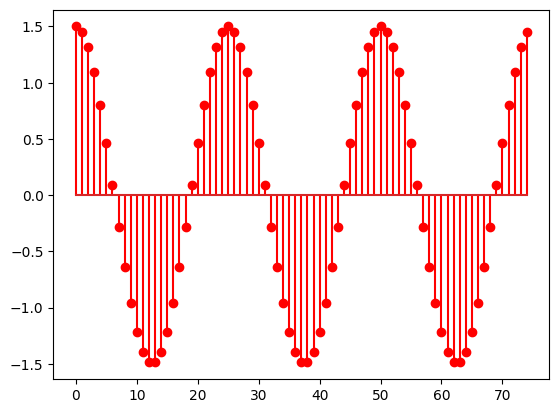

In [43]:
import sys

# 2. deixa o Python enxergar a pasta que CONTÉM a lib
if '/content' not in sys.path:
    sys.path.append('/content')

# 3. importa
from lib.luccasbi import *

In [51]:
import matplotlib.pyplot as plt

def SIGNALplot2(x, ms=2):
    '''
    Plota x com stem, com marcadores pequenos.

    x : sinal
    ms: tamanho das bolinhas (menor = mais fino)
    '''
    fig, ax = plt.subplots()
    markerline, stemlines, baseline = ax.stem(x, 'r')
    plt.setp(markerline, markersize=ms)
    plt.setp(stemlines, linewidth=0.8)
    plt.show()

P = 40 amostras | T = 0.800 s | f = 1.250 Hz (75 bpm)


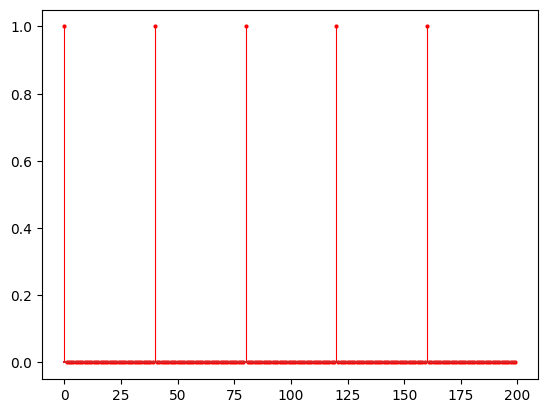

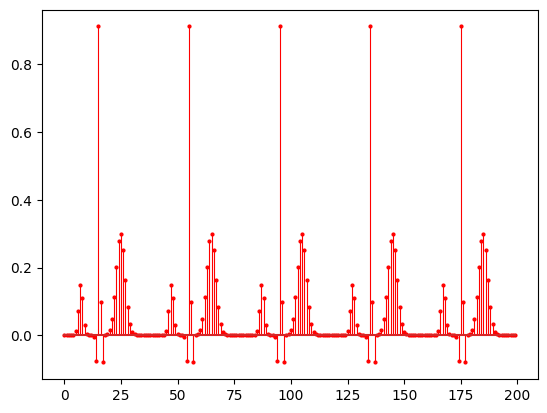

In [87]:
import numpy as np


bpm = 75
dur = 4
fs  = 50


N = int(dur * fs)
P = int(round(60 * fs / bpm))
T = P / fs

# Sinal: impulso a cada P amostras * forma de um batimento
trem = np.zeros(N)
for k in range(0, N, P):
    trem += SIGNALdelay(SIGNALgenerate(N, 'delta', {'k': 0}), k)

u = np.arange(P) / P
ondas = [(0.18, 0.025, 0.15), (0.35, 0.010, -0.12), (0.38, 0.012, 1.0),
         (0.41, 0.010, -0.25), (0.62, 0.050, 0.30)]
beat = sum(a * np.exp(-(u - mu)**2 / (2 * s**2)) for mu, s, a in ondas)
x = np.convolve(trem, beat)[:N]

print(f'P = {P} amostras | T = {T:.3f} s | f = {1/T:.3f} Hz ({bpm} bpm)')

SIGNALplot2(trem)   # impulsos: o espaçamento é o período
SIGNALplot2(x)      # batimento

In [88]:
def SIGNALperiodDemo(P, fs):
    T = P / fs
    print(f'O sinal se repete a cada {P} amostras, ou seja, a cada {T:.1f} s.')
    print(f'{1/T:.3f} repetições por segundo ou {1/T:.3f} Hz, equivalente a {60/T:.0f} batimentos por minuto.')

In [89]:
SIGNALperiodDemo(P, fs)

O sinal se repete a cada 40 amostras, ou seja, a cada 0.8 s.
1.250 repetições por segundo ou 1.250 Hz, equivalente a 75 batimentos por minuto.


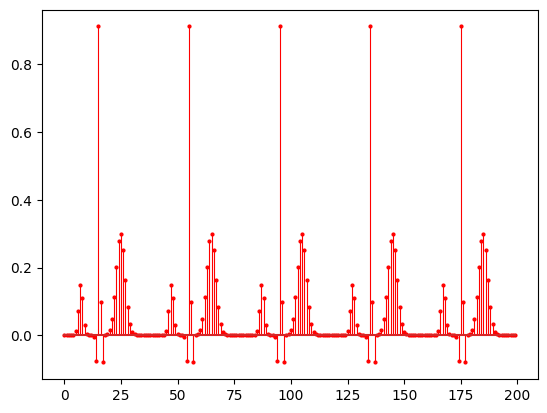

In [90]:

SIGNALplot2(x)      # batimento

In [ ]:
def SIGNALperiodDemo(x):

  return P